In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from data_analysis.config import load_config
from data_analysis.loaders.walker import load_walker
from data_analysis.loaders.hahn import load_hahn
from data_analysis.signatures import load_cas_signature, split_directions

In [3]:
cfg = load_config()
walker = load_walker(cfg)
hahn = load_hahn(cfg)
walker.counts.shape, hahn.counts.shape

((43346, 230), (21076, 847))

In [4]:
pd.crosstab(walker.meta["region"], walker.meta["group"])

group,S24,C24,SS,SC,CS,CC
region,,,,,,
BLA,7,6,7,7,5,6
Cpu,8,8,7,6,6,7
Hipp,7,8,6,7,6,5
NAc,8,8,6,5,5,7
PFC,7,8,7,7,5,7
VTA,6,6,6,5,3,5


In [5]:
pd.crosstab(hahn.meta["region"], hahn.meta["age_months"])

age_months,3,12,15,18,21,26,28
region,,,,,,,
cc,10,9,10,10,11,4,3
cer,10,9,10,10,11,5,3
cor,10,10,10,10,11,5,3
cp,9,10,10,10,11,5,3
ent,9,7,10,8,11,3,3
hi,10,9,9,10,11,5,3
hi2,10,10,10,10,10,5,3
hy,9,9,10,10,11,4,2
med,10,9,10,10,11,5,3


Text(0.5, 1.0, 'Walker library size by region × group')

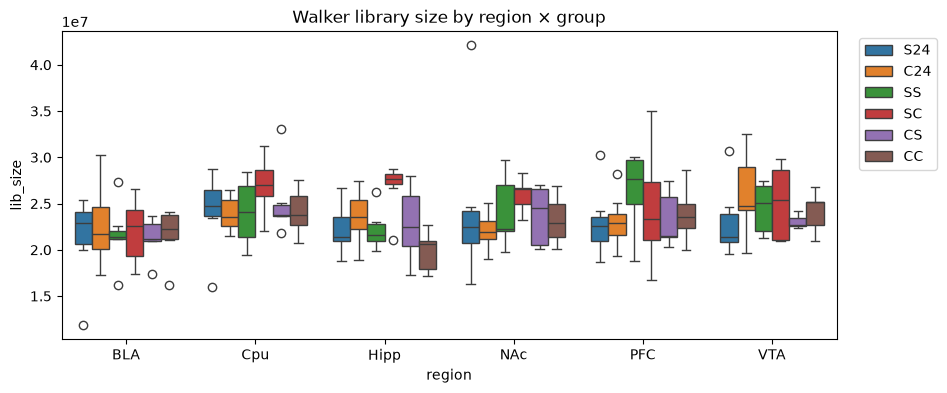

In [6]:
walker.meta["lib_size"] = walker.counts.sum()
plt.figure(figsize=(10, 4))
sns.boxplot(data=walker.meta, x="region", y="lib_size", hue="group")
plt.legend(bbox_to_anchor=(1.02, 1))
plt.title("Walker library size by region × group")

In [7]:
cas = load_cas_signature(cfg["data"]["hahn"]["supplement"])
up, down = split_directions(cas)

cp = hahn.subset(region="cp")
logcpm = np.log2(cp.counts / cp.counts.sum() * 1e6 + 1)

df = cp.meta.assign(Gpr17=logcpm.loc["Gpr17"], C4b=logcpm.loc["C4b"])
df.groupby("age_months")[["Gpr17", "C4b"]].mean().round(2)

,Gpr17,C4b
age_months,,
3,5.46,4.04
12,5.02,5.22
15,4.88,5.68
18,4.71,6.10
21,4.68,6.62
26,4.55,7.79
28,4.78,8.36


Text(0.5, 1.0, 'C4b in caudate putamen')

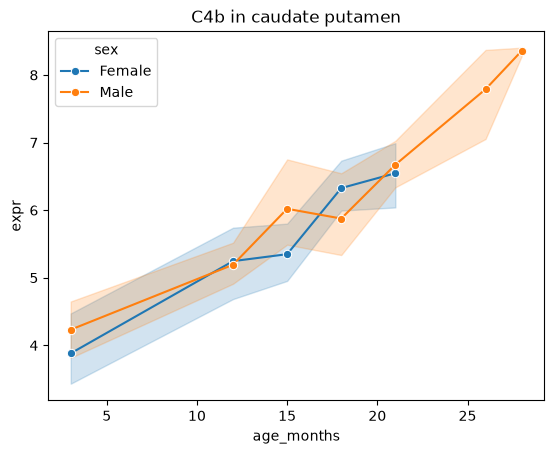

In [8]:
gene = "C4b"   # can change into any CAS DNA
sns.lineplot(data=cp.meta.assign(expr=logcpm.loc[gene]),
             x="age_months", y="expr", hue="sex", marker="o")
plt.title(f"{gene} in caudate putamen")